# Inferencia

Generación de predicciones de `SalePrice` para los datos crudos de `test.csv` con el modelo final del notebook `3.0-jec-entrenamiento-modelos` (Gradient Boosting reentrenado con el 100 % de `train.csv`, con su pipeline completo de ingeniería de características). Al final se construye y guarda un pipeline de inferencia que integra todo el flujo: datos crudos de entrada y precio en dólares de salida.

## 1. Librerías

Importación de las librerías de datos y visualización, y de la clase `InferencePipeline` del módulo del proyecto.

In [2]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

from proyecto_pd.modeling.predict import InferencePipeline

## 2. Configuración y carga

Lectura de `pipeline_config.yaml`, carga de los datos crudos de `test.csv` y del modelo final guardado en `models/final_model_pipeline.joblib`.

In [6]:
# Rutas configurables: cambia estas variables si las fuentes o destinos se mueven
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CONFIG_FILE = PROJECT_ROOT / "pipeline_config.yaml"
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
MODEL_FILE = MODELS_DIR / "final_model_pipeline.joblib"
INFERENCE_FILE = MODELS_DIR / "inference_pipeline.joblib"
PREDICTIONS_FILE = PROCESSED_DIR / "predictions.csv"

with open(CONFIG_FILE, encoding="utf-8") as f:
    config = yaml.safe_load(f)

TARGET = config["TARGET"]
MODEL_FEATURES = config["MODEL_FEATURES"]

test = pd.read_csv(RAW_DIR / "test.csv")
train = pd.read_csv(RAW_DIR / "train.csv")
final_pipeline = joblib.load(MODEL_FILE)

print(f"test: {test.shape}")
final_pipeline

test: (1459, 80)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputacion_categoricas', ...), ('imputacion_numericas', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['Gr...ea', 'Ga...ea', 'To...SF', '1s...SF', ...]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,imputation_method,'frequent'
,variables,"['Neighborhood', 'ExterQual', ...]"
,fill_value,'Missing'
,return_object,False


## 3. Generación de predicciones

Selección de las columnas de `MODEL_FEATURES` sobre los datos crudos, aplicación del pipeline completo (imputación, codificación, outliers, transformación, escalado y modelo) y reversión del target de escala `log1p` a dólares con `expm1`. Todos los parámetros del preprocesamiento provienen del ajuste con `train.csv`; los datos de test solo se transforman.

In [11]:
X_test = test[MODEL_FEATURES]

y_pred_log = final_pipeline.predict(X_test)
y_pred = np.expm1(y_pred_log)

predictions = pd.DataFrame({"Id": test["Id"], TARGET: y_pred})
predictions.head()

,Id,SalePrice
0,1461,123492.139976
1,1462,147511.916294
2,1463,188268.633931
3,1464,186111.996783
4,1465,192206.752606


## 4. Validación de las predicciones

Controles de calidad sobre la salida: una predicción por registro, sin valores nulos ni negativos, y comparación de la distribución de los precios predichos contra la de `SalePrice` en entrenamiento para detectar desplazamientos evidentes. Las líneas punteadas marcan la mediana de cada distribución, con el color de su curva.

Registros: 1459 de 1459
Nulos: 0 | Negativos: 0


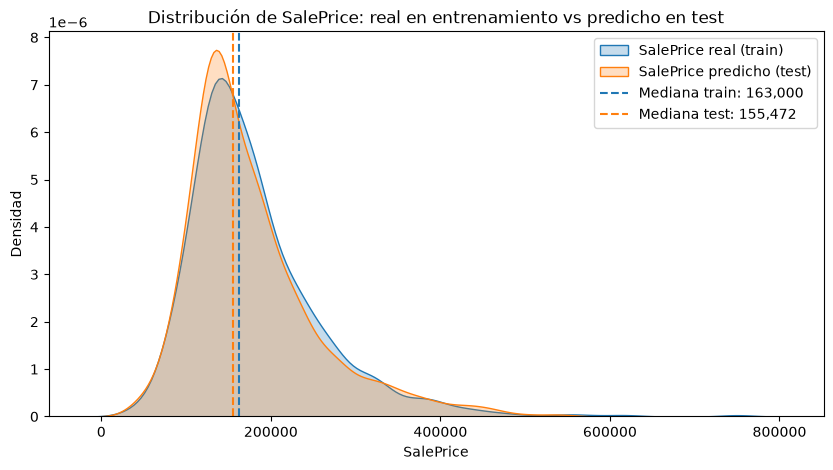

,train_real,test_predicho
count,1460.0,1459.0
mean,180921.0,176872.0
std,79443.0,76620.0
min,34900.0,40136.0
25%,129975.0,126577.0
50%,163000.0,155472.0
75%,214000.0,208184.0
max,755000.0,549667.0


In [12]:
print(f"Registros: {len(predictions)} de {len(test)}")
print(f"Nulos: {predictions[TARGET].isna().sum()} | Negativos: {(predictions[TARGET] <= 0).sum()}")

median_train = train[TARGET].median()
median_test = predictions[TARGET].median()

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(train[TARGET], fill=True, color="C0", label=f"{TARGET} real (train)", ax=ax)
sns.kdeplot(predictions[TARGET], fill=True, color="C1", label=f"{TARGET} predicho (test)", ax=ax)
ax.axvline(median_train, color="C0", linestyle="--", label=f"Mediana train: {median_train:,.0f}")
ax.axvline(median_test, color="C1", linestyle="--", label=f"Mediana test: {median_test:,.0f}")
ax.set_title(f"Distribución de {TARGET}: real en entrenamiento vs predicho en test")
ax.set_xlabel(TARGET)
ax.set_ylabel("Densidad")
ax.legend()
plt.show()

pd.DataFrame({"train_real": train[TARGET].describe(), "test_predicho": predictions[TARGET].describe()}).round(0)

## 5. Pipeline de inferencia

Integración del flujo completo en un único objeto `InferencePipeline` (definido en `proyecto_pd/modeling/predict.py`): recibe los datos crudos con todas sus columnas, selecciona `MODEL_FEATURES`, aplica el pipeline del modelo final y devuelve `SalePrice` en dólares. Se verifica que su salida coincide con las predicciones paso a paso y se guarda en `models/inference_pipeline.joblib`.

In [13]:
inference_pipeline = InferencePipeline(model_pipeline=final_pipeline, features=MODEL_FEATURES, target=TARGET)

inference_predictions = inference_pipeline.predict_frame(test)
print("Coincide con el paso a paso:", np.allclose(inference_predictions[TARGET], predictions[TARGET]))

joblib.dump(inference_pipeline, INFERENCE_FILE)
print(f"Guardado en: {INFERENCE_FILE.relative_to(PROJECT_ROOT)}")

Coincide con el paso a paso: True
Guardado en: models\inference_pipeline.joblib


## 6. Exportación de predicciones

Exportación de las predicciones en formato Kaggle (`Id`, `SalePrice`) a `data/processed/predictions.csv`. El mismo resultado puede generarse desde la terminal, en la raíz del proyecto, con:

```
python -m proyecto_pd.modeling.predict --input data/raw/test.csv --output data/processed/predictions.csv
```

In [14]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
inference_predictions.to_csv(PREDICTIONS_FILE, index=False)

print(f"{len(inference_predictions)} predicciones guardadas en {PREDICTIONS_FILE.relative_to(PROJECT_ROOT)}")

1459 predicciones guardadas en data\processed\predictions.csv
